In [4]:
!pip install "git+https://github.com/facebookresearch/pytorch3d.git@stable"



Defaulting to user installation because normal site-packages is not writeable
  Cloning https://github.com/facebookresearch/pytorch3d.git (to revision stable) to /tmp/pip-req-build-_u20o40f
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/pytorch3d.git /tmp/pip-req-build-_u20o40f
  Running command git checkout -q 75ebeeaea0908c5527e7b1e305fbc7681382db47
  Resolved https://github.com/facebookresearch/pytorch3d.git to commit 75ebeeaea0908c5527e7b1e305fbc7681382db47
  Preparing metadata (setup.py) ... done


In [5]:
!pip install numpy torch smplx pytorch3d matplotlib opencv-python

Defaulting to user installation because normal site-packages is not writeable


In [6]:
!pip install numpy==1.23.5


Defaulting to user installation because normal site-packages is not writeable


In [7]:
from smplx import SMPL

smpl_model_path = '/x4/ljiao/Bhanu/PARE/data/body_models/smpl/SMPL_NEUTRAL.pkl'
smpl = SMPL(model_path=smpl_model_path, gender='NEUTRAL')

In [8]:
import os
import joblib
import numpy as np
import torch

# Path to your PARE output file
file_path = '/x4/ljiao/Bhanu/PARE/logs/demo/Bhanu_/pare_output.pkl'

# Use joblib for safer memory-efficient loading
data = joblib.load(file_path)

print("📂 Loaded data type:", type(data))

# If it's a list of frames
if isinstance(data, list):
    print(f"✅ Total frames: {len(data)}")
    print(f"📄 Type of data[0]: {type(data[0])}")
    
    # Peek into the first frame
    frame0 = data[0]
    print("\n🔍 Keys in frame 0:")
    for k, v in frame0.items():
        if isinstance(v, np.ndarray):
            print(f"  - {k}: {v.shape} (dtype: {v.dtype})")
        else:
            print(f"  - {k}: {type(v)}")
else:
    print("❌ Unexpected data structure (not a list). Aborting.")




📂 Loaded data type: <class 'dict'>
❌ Unexpected data structure (not a list). Aborting.


In [83]:
print(f"🔍 Keys inside data[1]: {list(data[1].keys())}")
print("🔍 Inspecting keys inside data[1]...\n")
for key in data[1].keys():
    value = data[1][key]
    print(f"🔑 {key}: ", end='')
    if value is None:
        print("❌ NoneType")
    else:
        try:
            print(f"✅ Type: {type(value)}, Shape: {np.shape(value)}")
        except Exception as e:
            print(f"⚠️ Could not get shape, Type: {type(value)}")


🔍 Keys inside data[1]: ['pred_cam', 'orig_cam', 'verts', 'pose', 'betas', 'joints3d', 'joints2d', 'smpl_joints2d', 'bboxes', 'frame_ids']
🔍 Inspecting keys inside data[1]...

🔑 pred_cam: ✅ Type: <class 'numpy.ndarray'>, Shape: (297, 3)
🔑 orig_cam: ✅ Type: <class 'numpy.ndarray'>, Shape: (297, 4)
🔑 verts: ✅ Type: <class 'numpy.ndarray'>, Shape: (297, 6890, 3)
🔑 pose: ✅ Type: <class 'numpy.ndarray'>, Shape: (297, 24, 3, 3)
🔑 betas: ✅ Type: <class 'numpy.ndarray'>, Shape: (297, 10)
🔑 joints3d: ✅ Type: <class 'numpy.ndarray'>, Shape: (297, 49, 3)
🔑 joints2d: ❌ NoneType
🔑 smpl_joints2d: ✅ Type: <class 'numpy.ndarray'>, Shape: (297, 49, 2)
🔑 bboxes: ✅ Type: <class 'numpy.ndarray'>, Shape: (297, 4)
🔑 frame_ids: ✅ Type: <class 'numpy.ndarray'>, Shape: (297,)


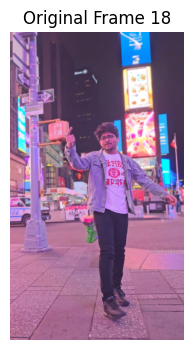

In [31]:
import cv2
from matplotlib import pyplot as plt

# Get the correct frame index
frame_index = 18  # index into verts_all[], joints[], etc.
frame_number = int(frame_data['frame_ids'][frame_index])  # e.g., 11

# Construct the file path for the corresponding image
img_path = f"/x4/ljiao/Bhanu/PARE/logs/demo/Bhanu_/tmp_images/{frame_number:06d}.png"

# Load and display the image
img = cv2.imread(img_path)
if img is None:
    print(f"❌ Image not found: {img_path}")
else:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(4, 4))
    plt.imshow(img_rgb)
    plt.title(f"Original Frame {frame_number}")
    plt.axis('off')
    plt.show()


✅ Loaded type: <class 'dict'> | Top-level keys: [2, 1, 4, 5, 8]
ℹ️ Total sub-frames in frame 1: 297
✅ Original mesh shape: (6890, 3)


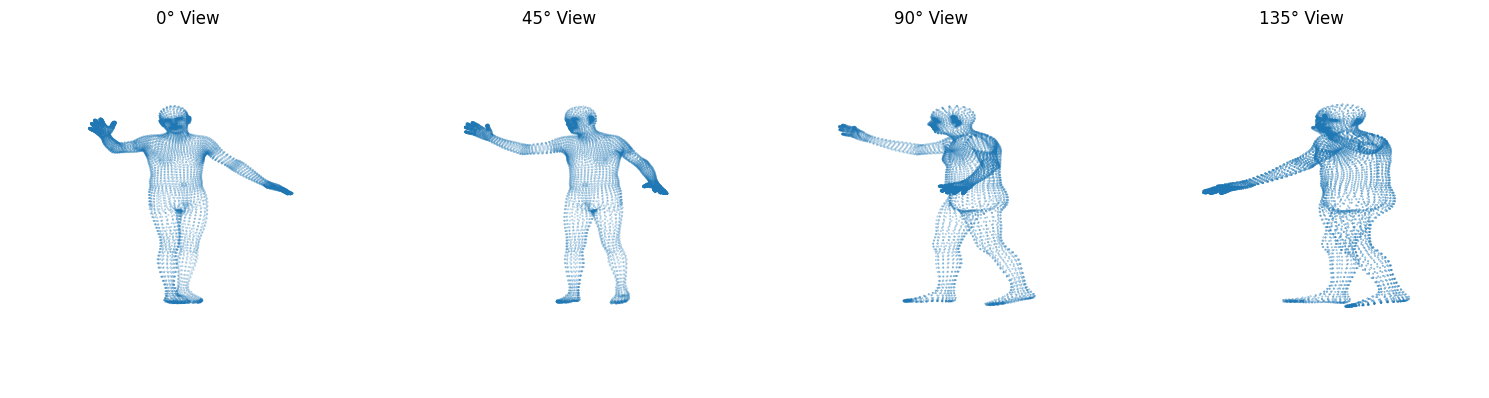

✅ Saved individual skeleton mesh images for each rotation.


In [97]:
import joblib
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

# ===== Step 1: Load the PARE Output File =====
file_path = '/x4/ljiao/Bhanu/PARE/logs/demo/Bhanu_/pare_output.pkl'

# Load the file using joblib (memory-efficient)
data = joblib.load(file_path)
print(f"✅ Loaded type: {type(data)} | Top-level keys: {list(data.keys())[:5]}")

# ===== Step 2: Select a Frame and Extract Vertices =====
frame_key = 1  # You can change to 2, 4, etc. as needed
frame_data = data[frame_key]

verts_all = frame_data['verts']  # Shape: (num_frames, 6890, 3)
print(f"ℹ️ Total sub-frames in frame {frame_key}: {verts_all.shape[0]}")

# Pick a single sub-frame from that sequence
vertices = verts_all[frame_index-1]  # Shape: (6890, 3)
print("✅ Original mesh shape:", vertices.shape)

# ===== Step 3: Define a Rotation Function =====
def rotate_mesh_y(vertices, angle_deg):
    angle_rad = np.radians(angle_deg)
    rot_matrix = np.array([
        [np.cos(angle_rad), 0, np.sin(angle_rad)],
        [0, 1, 0],
        [-np.sin(angle_rad), 0, np.cos(angle_rad)]
    ])
    return vertices @ rot_matrix.T

def mirror_mesh_x(vertices):
    mirrored = vertices.copy()
    mirrored[:, 0] = -mirrored[:, 0]  # Flip X
    return mirrored

# ===== Step 4: Generate Rotated Views =====
angles = [0, 45, 90, 135]
#rotated_meshes = [rotate_mesh_y(vertices, angle) for angle in angles]
rotated_meshes = [rotate_mesh_y(vertices, angle + 180) for angle in angles]

#mirrored_vertices = mirror_mesh_x(vertices)
#rotated_meshes = [rotate_mesh_y(mirrored_vertices, angle) for angle in angles]


# ===== Step 5: Visualize the Rotated Meshes =====
def show_mesh(vertices, ax, title=""):
    ax.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2], s=0.1)
    ax.set_title(title)
    ax.view_init(elev=90, azim=90)
    ax.axis('off')

fig = plt.figure(figsize=(15, 4))
for i, mesh in enumerate(rotated_meshes):
    ax = fig.add_subplot(1, 4, i + 1, projection='3d')
    show_mesh(mesh, ax, f"{angles[i]}° View")
    plt.savefig(f"skeleton_view_{angles[i]}deg.png", dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

# Save each mesh as a separate image
for i, mesh in enumerate(rotated_meshes):
    fig = plt.figure(figsize=(4, 4))
    ax = fig.add_subplot(111, projection='3d')
    show_mesh(mesh, ax, f"{angles[i]}° View")
    plt.tight_layout()
    plt.savefig(f"skeleton_view_{angles[i]}deg.png", dpi=300, bbox_inches='tight')
    plt.close(fig)  # Close to avoid memory leaks
print("✅ Saved individual skeleton mesh images for each rotation.")



✅ Loaded type: <class 'dict'> | Top-level keys: [2, 1, 4, 5, 8]
✅ Mesh shape: (6890, 3) | Joints shape: (49, 3)


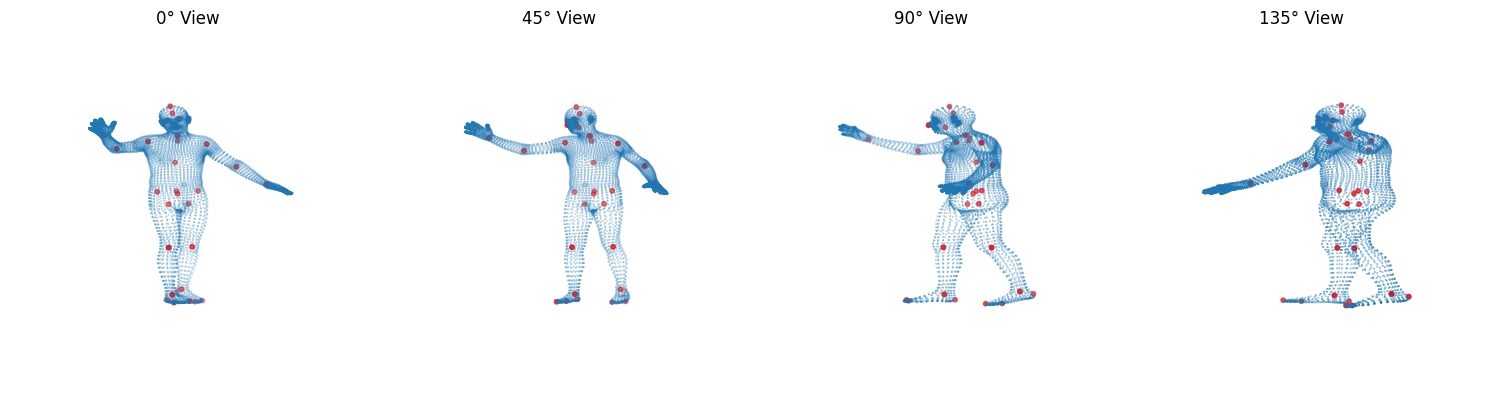

In [72]:
import joblib
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

# ===== Step 1: Load the PARE Output File =====
file_path = '/x4/ljiao/Bhanu/PARE/logs/demo/Bhanu_/pare_output.pkl'
data = joblib.load(file_path)
print(f"✅ Loaded type: {type(data)} | Top-level keys: {list(data.keys())[:5]}")

# ===== Step 2: Select a Frame and Extract Vertices and Joints =====
frame_key = 1
frame_index = 18  # You can modify as needed
frame_data = data[frame_key]

verts_all = frame_data['verts']  # (num_frames, 6890, 3)
joints_all = frame_data['joints3d']  # (num_frames, 49, 3) or (num_frames, 33, 3)

vertices = verts_all[frame_index - 1]
joints3d = joints_all[frame_index - 1]
print("✅ Mesh shape:", vertices.shape, "| Joints shape:", joints3d.shape)

# ===== Step 3: Rotation Function =====
def rotate_mesh_y(points, angle_deg):
    angle_rad = np.radians(angle_deg)
    rot_matrix = np.array([
        [np.cos(angle_rad), 0, np.sin(angle_rad)],
        [0, 1, 0],
        [-np.sin(angle_rad), 0, np.cos(angle_rad)]
    ])
    return points @ rot_matrix.T

# ===== Step 4: Generate Rotated Meshes and Joints =====
angles = [0, 45, 90, 135]
rotated_meshes = [rotate_mesh_y(vertices, angle + 180) for angle in angles]
rotated_joints = [rotate_mesh_y(joints3d, angle + 180) for angle in angles]

# ===== Step 5: Visualization with Joints in Red =====
def show_mesh_with_joints(vertices, joints, ax, title=""):
    ax.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2], s=0.1, label='Mesh')
    ax.scatter(joints[:, 0], joints[:, 1], joints[:, 2], c='red', s=10, label='Joints')
    ax.set_title(title)
    ax.view_init(elev=90, azim=90)
    ax.axis('off')

fig = plt.figure(figsize=(15, 4))
for i in range(4):
    ax = fig.add_subplot(1, 4, i + 1, projection='3d')
    show_mesh_with_joints(rotated_meshes[i], rotated_joints[i], ax, f"{angles[i]}° View")

plt.tight_layout()
plt.show()


📌 SMPL 2D Joints:
 [[ 605.922    703.8489 ]
 [ 618.4566   761.671  ]
 [ 511.9262   795.56134]
 [ 401.187    839.6416 ]
 [ 361.59317  770.1472 ]
 [ 724.54663  807.17004]
 [ 833.153    933.39935]
 [ 942.43054 1031.451  ]
 [ 619.1444  1084.9391 ]
 [ 585.87317 1142.7559 ]
 [ 587.4215  1382.2195 ]
 [ 600.20874 1642.6659 ]
 [ 658.3543  1140.268  ]
 [ 671.5297  1380.5096 ]
 [ 632.6316  1622.1525 ]
 [ 582.7757   681.5791 ]
 [ 623.8282   673.34644]
 [ 566.4185   692.24146]
 [ 657.1958   673.5421 ]
 [ 681.97705 1687.7375 ]
 [ 709.21094 1683.7183 ]
 [ 616.5002  1635.0343 ]
 [ 662.9627  1672.4365 ]
 [ 606.7215  1680.4094 ]
 [ 582.9755  1673.5309 ]
 [ 600.20874 1642.6659 ]
 [ 587.4215  1382.2195 ]
 [ 545.2282  1074.0533 ]
 [ 693.2992  1068.5697 ]
 [ 671.5297  1380.5096 ]
 [ 632.6316  1622.1525 ]
 [ 361.59317  770.1472 ]
 [ 401.187    839.6416 ]
 [ 511.9262   795.56134]
 [ 724.54663  807.17004]
 [ 833.153    933.39935]
 [ 942.43054 1031.451  ]
 [ 618.5079   761.4705 ]
 [ 592.5564   600.90924]
 [ 614

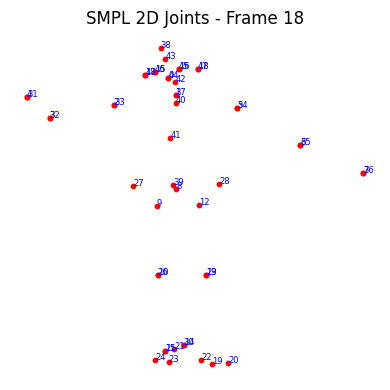

In [87]:
import matplotlib.pyplot as plt

frame_index = 18  # same index you've used
joints2d = data[1]['smpl_joints2d'][frame_index - 1]

print("📌 SMPL 2D Joints:\n", joints2d)
print("🔢 Number of SMPL 2D joints:", joints2d.shape[0])

# Visualize
plt.figure(figsize=(4, 4))
plt.scatter(joints2d[:, 0], joints2d[:, 1], c='red', s=10)
for i, (x, y) in enumerate(joints2d):
    plt.text(x, y, str(i), fontsize=6, color='blue')
plt.gca().invert_yaxis()
plt.title(f"SMPL 2D Joints - Frame {frame_index}")
plt.axis('off')
plt.tight_layout()
plt.show()


In [86]:
print("📌 3D Joint Coordinates:\n", joints3d)
print("🔢 Number of 3D joints:", joints3d.shape[0])

📌 3D Joint Coordinates:
 [[-2.38997787e-02 -8.35951746e-01 -1.81459874e-01]
 [-4.05657198e-03 -7.46317208e-01 -2.95802578e-03]
 [-1.74370497e-01 -6.91433370e-01 -5.10094725e-02]
 [-3.49912614e-01 -6.18832886e-01 -2.32979730e-01]
 [-4.10651505e-01 -7.26206660e-01 -4.68325108e-01]
 [ 1.65962607e-01 -6.74310982e-01  6.19969368e-02]
 [ 3.40394974e-01 -4.72355843e-01  1.10334083e-01]
 [ 5.14573276e-01 -3.14461917e-01 -1.57855451e-03]
 [-2.97688623e-03 -2.28913039e-01  2.44536959e-02]
 [-5.62204905e-02 -1.36281580e-01 -6.09306619e-04]
 [-5.35288826e-02  2.46224344e-01 -1.12845793e-01]
 [-3.31150666e-02  6.62208200e-01 -1.08494341e-01]
 [ 5.98435327e-02 -1.40315160e-01  5.01704253e-02]
 [ 8.10221136e-02  2.45151117e-01  1.08875647e-01]
 [ 1.85610279e-02  6.35035694e-01  2.40835384e-01]
 [-6.08825609e-02 -8.72095466e-01 -1.44525483e-01]
 [ 4.63452563e-03 -8.85071278e-01 -1.53786838e-01]
 [-8.72501805e-02 -8.56767476e-01 -4.41378504e-02]
 [ 5.79227209e-02 -8.86338472e-01 -6.33572638e-02]
 [ 9.7

✅ Saved individual skeleton mesh images for each rotation.


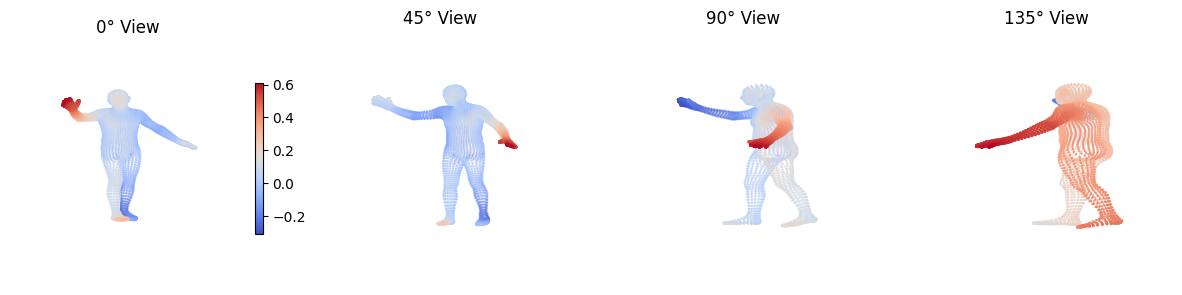

In [99]:
def show_mesh(vertices, ax, fig, title="", add_colorbar=False):
    sc = ax.scatter(
        vertices[:, 0], vertices[:, 1], vertices[:, 2],
        c=vertices[:, 2], cmap='coolwarm', s=0.5
    )
    ax.set_title(title)
    ax.view_init(elev=90, azim=90)
    ax.axis('off')
    if add_colorbar:
        fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.04)


fig = plt.figure(figsize=(15, 4))
for i, mesh in enumerate(rotated_meshes):
    ax = fig.add_subplot(1, 4, i + 1, projection='3d')
    show_mesh(mesh, ax, fig, f"{angles[i]}° View", add_colorbar=(i==0))


In [100]:
import matplotlib.pyplot as plt
import numpy as np

def show_mesh(vertices, ax, fig, title="", add_colorbar=False):
    sc = ax.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2], s=0.1, c=vertices[:, 1], cmap='viridis')
    ax.set_title(title)
    ax.view_init(elev=90, azim=90)
    ax.axis('off')
    if add_colorbar:
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)

# Loop and save each image separately
for i, mesh in enumerate(rotated_meshes):
    fig = plt.figure(figsize=(4, 4))
    ax = fig.add_subplot(1, 1, 1, projection='3d')
    show_mesh(mesh, ax, fig, f"{angles[i]}° View", add_colorbar=True)
    plt.tight_layout()
    save_path = f"skeleton_mesh_{angles[i]}deg.png"
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close(fig)
    print(f"✅ Saved {save_path}")


✅ Saved skeleton_mesh_0deg.png
✅ Saved skeleton_mesh_45deg.png
✅ Saved skeleton_mesh_90deg.png
✅ Saved skeleton_mesh_135deg.png


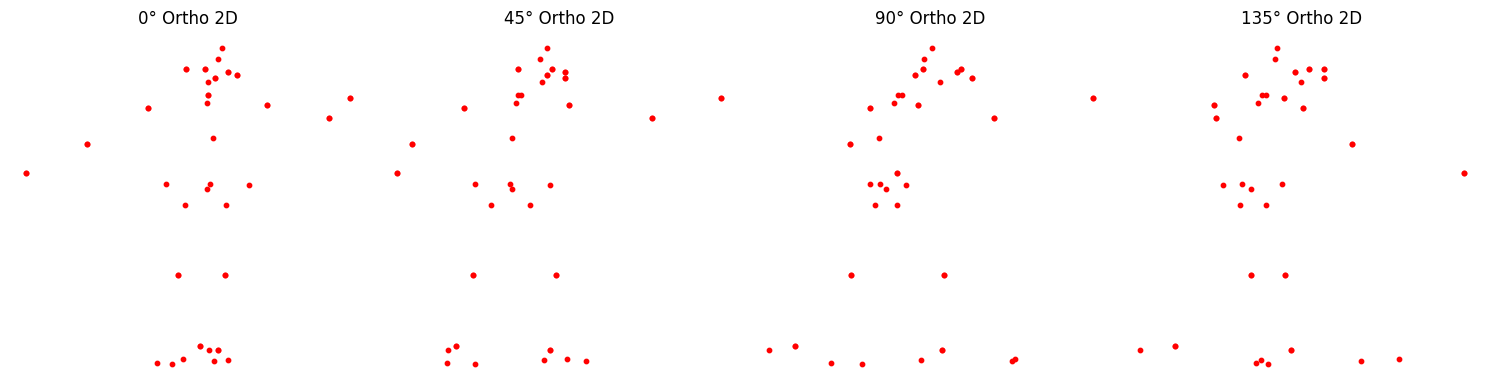

In [113]:
def orthographic_project(joints_3d, img_size=224):
    # Simple orthographic projection: just take X and Y
    cam_center = np.array([img_size / 2, img_size / 2])
    projected = joints_3d[:, [0, 1]] + cam_center  # shift to image center
    return projected
    
projected_joints_2d = [orthographic_project(j3d) for j3d in rotated_joints]

fig, axs = plt.subplots(1, 4, figsize=(15, 4))
for i, kp2d in enumerate(projected_joints_2d):
    #print(f"🔍 2D Coordinates for {angles[i]}° View:\n", kp2d)
    axs[i].scatter(kp2d[:, 0], kp2d[:, 1], s=10, c='red')
    axs[i].invert_yaxis()
    axs[i].axis('off')
    axs[i].set_title(f"{angles[i]}° Ortho 2D")
plt.tight_layout()
plt.show()



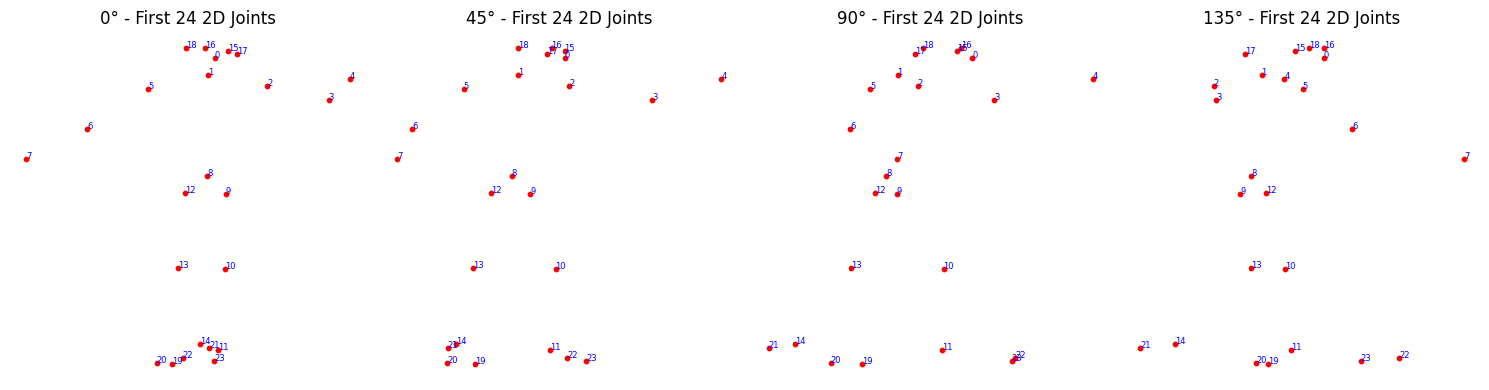

In [112]:
import matplotlib.pyplot as plt
import numpy as np

def orthographic_project(joints_3d, img_size=224):
    cam_center = np.array([img_size / 2, img_size / 2])
    projected = joints_3d[:, [0, 1]] + cam_center
    return projected

# Project and slice only the first 24 joints
projected_joints_2d = [orthographic_project(j3d)[:24] for j3d in rotated_joints]

# Plotting
fig, axs = plt.subplots(1, 4, figsize=(15, 4))
for i, kp2d in enumerate(projected_joints_2d):
    axs[i].scatter(kp2d[:, 0], kp2d[:, 1], s=10, c='red')
    for j, (x, y) in enumerate(kp2d):
        axs[i].text(x, y, str(j), fontsize=6, color='blue')
    axs[i].invert_yaxis()
    axs[i].axis('off')
    axs[i].set_title(f"{angles[i]}° - First 24 2D Joints")
plt.tight_layout()
plt.show()


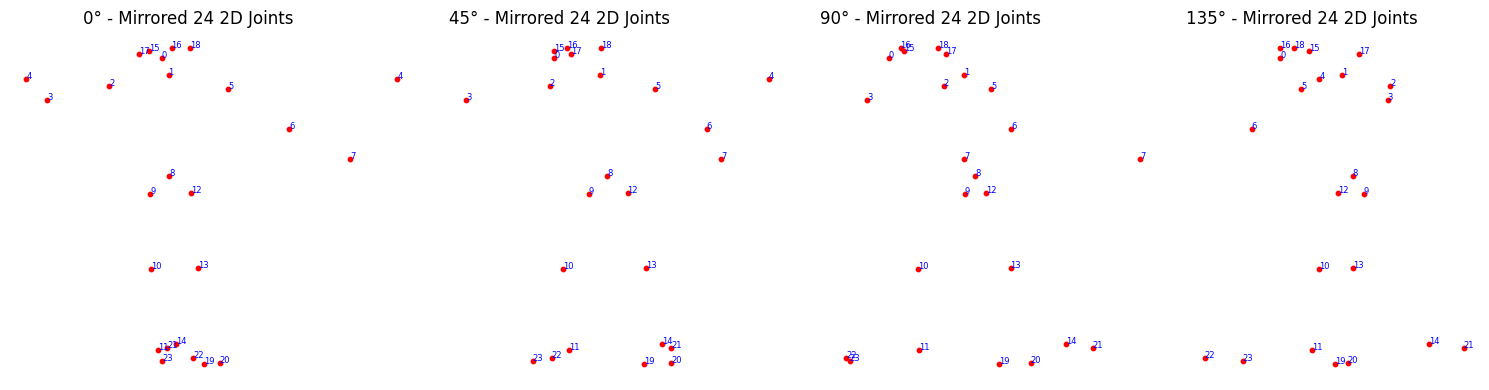

In [114]:
import matplotlib.pyplot as plt
import numpy as np

def orthographic_project(joints_3d, img_size=224, mirror=False):
    cam_center = np.array([img_size / 2, img_size / 2])
    projected = joints_3d[:, [0, 1]] + cam_center
    if mirror:
        projected[:, 0] = img_size - projected[:, 0]  # Flip X
    return projected

# Project only first 24 joints with mirror
projected_joints_2d = [orthographic_project(j3d, mirror=True)[:24] for j3d in rotated_joints]

# Plotting
fig, axs = plt.subplots(1, 4, figsize=(15, 4))
for i, kp2d in enumerate(projected_joints_2d):
    axs[i].scatter(kp2d[:, 0], kp2d[:, 1], s=10, c='red')
    for j, (x, y) in enumerate(kp2d):
        axs[i].text(x, y, str(j), fontsize=6, color='blue')
    axs[i].invert_yaxis()
    axs[i].axis('off')
    axs[i].set_title(f"{angles[i]}° - Mirrored 24 2D Joints")
plt.tight_layout()
plt.show()


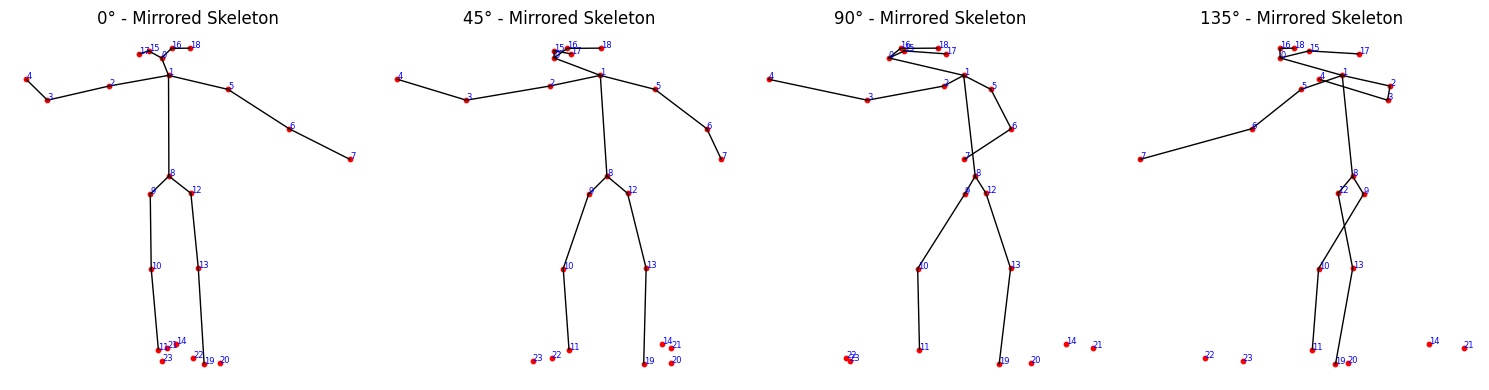

In [121]:
import matplotlib.pyplot as plt
import numpy as np

smpl_bones_24 = [
    (0, 1), (0, 15),(15,17), (0, 16),(16, 18),           # Left a
    (1, 5), (5, 6), (6, 7),           # Right leg
    (1, 2), (2, 3), (3, 4),                # Spine
    (1, 8), 
    (8, 9),(8, 12),                       # Left arm
    (9, 10),(10, 11),                       # Right arm
    (12, 13), (13, 19)                      # Neck + head
                  
]
'''
# Define which joints to connect (simplified skeleton for SMPL 0–23)
smpl_bones_24 = [
    (0, 1), (1, 2), (2, 3), (3, 4),           # Left a
    (0, 5), (5, 6), (6, 7),           # Right leg
    (1, 8), (9, 10), (10, 11),                # Spine
    (11, 12), (12, 13),                       # Left arm
    (11, 14), (14, 15),                       # Right arm
    (10, 16), (16, 17),                       # Neck + head
    (13, 18), (18, 19),                       # Left hand (optional)
    (15, 20), (20, 21),                       # Right hand (optional)
    (11, 22), (11, 23)                        # Shoulders (optional)
]
'''

# Orthographic projection + optional mirroring
def orthographic_project(joints_3d, img_size=224, mirror=False):
    cam_center = np.array([img_size / 2, img_size / 2])
    projected = joints_3d[:, [0, 1]] + cam_center
    if mirror:
        projected[:, 0] = img_size - projected[:, 0]
    return projected

# Project the joints (first 24, mirrored)
projected_joints_2d = [orthographic_project(j3d, mirror=True)[:24] for j3d in rotated_joints]

# Plot
fig, axs = plt.subplots(1, 4, figsize=(15, 4))
for i, kp2d in enumerate(projected_joints_2d):
    axs[i].scatter(kp2d[:, 0], kp2d[:, 1], s=10, c='red')
    for j, (x, y) in enumerate(kp2d):
        axs[i].text(x, y, str(j), fontsize=6, color='blue')

    # Draw lines (bones)
    for bone in smpl_bones_24:
        j1, j2 = bone
        x = [kp2d[j1, 0], kp2d[j2, 0]]
        y = [kp2d[j1, 1], kp2d[j2, 1]]
        axs[i].plot(x, y, 'black', linewidth=1)

    axs[i].invert_yaxis()
    axs[i].axis('off')
    axs[i].set_title(f"{angles[i]}° - Mirrored Skeleton")
plt.tight_layout()
plt.show()


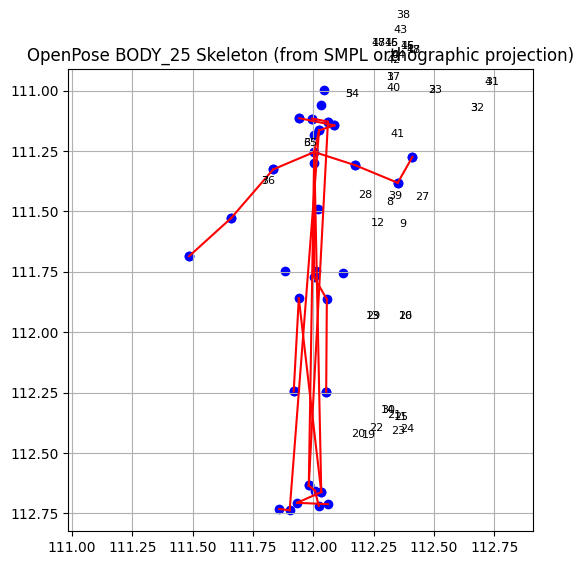

In [109]:
import matplotlib.pyplot as plt
import numpy as np

# Replace with your 2D joint data (shape: 49 x 2)
joints_2d = np.array([
    [112.02389978, 111.16404825],
    [112.00405657, 111.25368279],
    [112.1743705,  111.30856663],
    [112.34991261, 111.38116711],
    [112.4106515,  111.27379334],
    [111.83403739, 111.32568902],
    [111.65960503, 111.52764416],
    [111.48542672, 111.68553808],
    [112.00297689, 111.77108696],
    [112.05622049, 111.86371842],
    [112.05352888, 112.24622434],
    [112.03311507, 112.6622082 ],
    [111.94015647, 111.85968484],
    [111.91897789, 112.24515112],
    [111.98143897, 112.63503569],
    [112.06088256, 111.12790453],
    [111.99536547, 111.11492872],
    [112.08725018, 111.14323252],
    [111.94207728, 111.11366153],
    [111.90225189, 112.73767161],
    [111.85839461, 112.73259079],
    [112.00745623, 112.65681469],
    [111.93302692, 112.70664221],
    [112.02251062, 112.719473  ],
    [112.06074165, 112.71240366],
    [112.03311507, 112.6622082 ],
    [112.05352888, 112.24622434],
    [112.12121294, 111.75380835],
    [111.88412715, 111.74472967],
    [111.91897789, 112.24515112],
    [111.98143897, 112.63503569],
    [112.4106515,  111.27379334],
    [112.34991261, 111.38116711],
    [112.1743705,  111.30856663],
    [111.83403739, 111.32568902],
    [111.65960503, 111.52764416],
    [111.48542672, 111.68553808],
    [112.00396574, 111.25351846],
    [112.04537772, 110.99796677],
    [112.01054438, 111.74829376],
    [112.00321183, 111.29879844],
    [112.01910764, 111.49084181],
    [112.00423655, 111.18411285],
    [112.03273143, 111.05813253],
    [112.02389978, 111.16404825],
    [111.99536547, 111.11492872],
    [112.06088256, 111.12790453],
    [111.94207728, 111.11366153],
    [112.08725018, 111.14323252],
])

# BODY_25 joint connections
BODY_25_PAIRS = [
    (0, 1), (1, 2), (2, 3), (3, 4),         # Mid body / spine
    (1, 5), (5, 6), (6, 7),                 # Left arm
    (1, 8), (8, 9), (9, 10),                # Right arm
    (1, 11), (11, 12), (12, 13),            # Left leg
    (1, 14), (14, 15), (15, 16),            # Right leg
    (0, 17), (17, 18),                      # Left eye/ear
    (0, 19), (19, 20),                      # Right eye/ear
    (14, 21), (11, 22),                     # Ankles to big toes
    (21, 23), (22, 24)                      # Toes
]

# --- Plotting ---
plt.figure(figsize=(6, 6))
for i, (x, y) in enumerate(joints_2d):
    plt.scatter(x, y, c='blue')
    plt.text(x + 0.3, y - 0.3, f"{i}", fontsize=8)

# Draw connections
for (i, j) in BODY_25_PAIRS:
    if i < len(joints_2d) and j < len(joints_2d):
        xi, yi = joints_2d[i]
        xj, yj = joints_2d[j]
        plt.plot([xi, xj], [yi, yj], 'r-', linewidth=1.5)

plt.title("OpenPose BODY_25 Skeleton (from SMPL orthographic projection)")
plt.gca().invert_yaxis()  # Y-axis top-down like image coordinates
plt.axis("equal")
plt.grid(True)
plt.show()


In [110]:
import numpy as np

# Dummy example: replace this with actual OpenPose BODY_25 output
# Format: [x, y, confidence] for each of 25 keypoints
body_25_keypoints = np.array([
    [112.02, 111.16, 0.99],  # 0 - Nose
    [112.00, 111.25, 0.98],  # 1 - Neck
    [112.17, 111.30, 0.95],  # 2 - RShoulder
    [112.34, 111.38, 0.93],  # 3 - RElbow
    [112.41, 111.27, 0.91],  # 4 - RWrist
    [111.83, 111.32, 0.97],  # 5 - LShoulder
    [111.65, 111.52, 0.96],  # 6 - LElbow
    [111.48, 111.68, 0.94],  # 7 - LWrist
    [112.00, 111.77, 0.89],  # 8 - MidHip
    [112.05, 111.86, 0.85],  # 9 - RHip
    [112.05, 112.24, 0.88],  # 10 - RKnee
    [112.03, 112.66, 0.92],  # 11 - RAnkle
    [111.94, 111.85, 0.84],  # 12 - LHip
    [111.91, 112.24, 0.82],  # 13 - LKnee
    [111.98, 112.63, 0.83],  # 14 - LAnkle
    [112.06, 111.12, 0.90],  # 15 - REye
    [111.99, 111.11, 0.89],  # 16 - LEye
    [112.08, 111.14, 0.88],  # 17 - REar
    [111.94, 111.11, 0.87],  # 18 - LEar
    [111.90, 112.73, 0.80],  # 19 - LBigToe
    [111.85, 112.73, 0.79],  # 20 - LSmallToe
    [112.00, 112.65, 0.81],  # 21 - LHeel
    [111.93, 112.70, 0.83],  # 22 - RBigToe
    [112.02, 112.71, 0.82],  # 23 - RSmallToe
    [112.06, 112.71, 0.81],  # 24 - RHeel
])

# Print all keypoints
print("OpenPose BODY_25 Joint Coordinates:\n")
for i, (x, y, c) in enumerate(body_25_keypoints):
    print(f"Joint {i:2d}: x = {x:.2f}, y = {y:.2f}, confidence = {c:.2f}")

# Count valid (non-zero confidence) joints
valid_joints = np.sum(body_25_keypoints[:, 2] > 0.0)
print(f"\n✅ Total valid joints detected: {valid_joints} / {len(body_25_keypoints)}")


OpenPose BODY_25 Joint Coordinates:

Joint  0: x = 112.02, y = 111.16, confidence = 0.99
Joint  1: x = 112.00, y = 111.25, confidence = 0.98
Joint  2: x = 112.17, y = 111.30, confidence = 0.95
Joint  3: x = 112.34, y = 111.38, confidence = 0.93
Joint  4: x = 112.41, y = 111.27, confidence = 0.91
Joint  5: x = 111.83, y = 111.32, confidence = 0.97
Joint  6: x = 111.65, y = 111.52, confidence = 0.96
Joint  7: x = 111.48, y = 111.68, confidence = 0.94
Joint  8: x = 112.00, y = 111.77, confidence = 0.89
Joint  9: x = 112.05, y = 111.86, confidence = 0.85
Joint 10: x = 112.05, y = 112.24, confidence = 0.88
Joint 11: x = 112.03, y = 112.66, confidence = 0.92
Joint 12: x = 111.94, y = 111.85, confidence = 0.84
Joint 13: x = 111.91, y = 112.24, confidence = 0.82
Joint 14: x = 111.98, y = 112.63, confidence = 0.83
Joint 15: x = 112.06, y = 111.12, confidence = 0.90
Joint 16: x = 111.99, y = 111.11, confidence = 0.89
Joint 17: x = 112.08, y = 111.14, confidence = 0.88
Joint 18: x = 111.94, y = 1

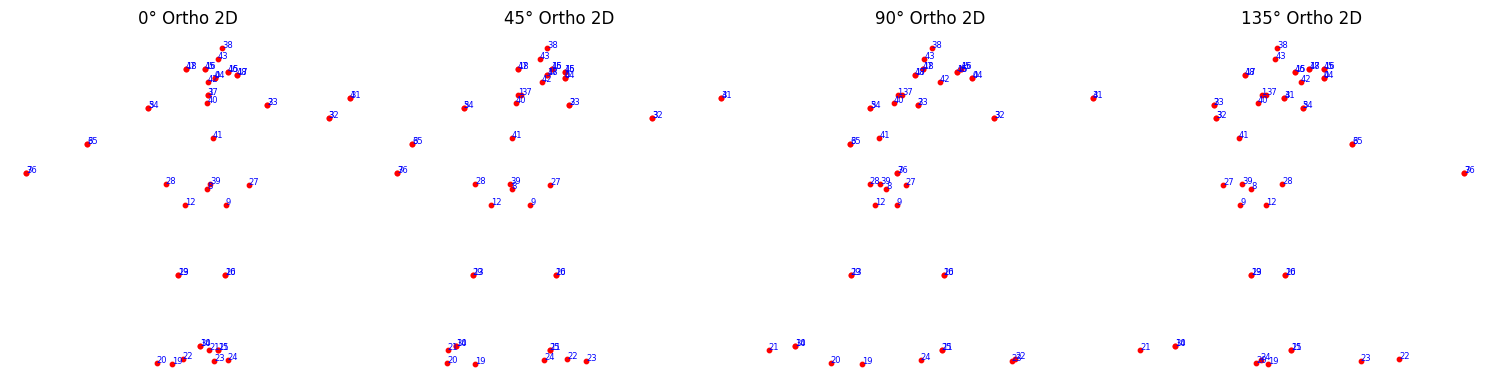

In [76]:
fig, axs = plt.subplots(1, 4, figsize=(15, 4))
for i, kp2d in enumerate(projected_joints_2d):
    axs[i].scatter(kp2d[:, 0], kp2d[:, 1], s=10, c='red')
    for j, (x, y) in enumerate(kp2d):  # Annotate each joint
        axs[i].text(x, y, str(j), fontsize=6, color='blue')
    axs[i].invert_yaxis()
    axs[i].axis('off')
    axs[i].set_title(f"{angles[i]}° Ortho 2D")

plt.tight_layout()
plt.show()


In [60]:
def smpl_to_mediapipe(joints_3d, img_size=224):
    # Orthographic projection
    cam_center = np.array([img_size / 2, img_size / 2])
    joints_2d = joints_3d[:, [0, 1]] + cam_center

    # Initialize with NaNs
    mp_joints_2d = np.full((33, 2), np.nan)

    # Map SMPL joints to MediaPipe indices (approximate)
    mapping = {
    0: 12,   # Nose ≈ Pelvis (approx)
    11: 2,   # Left shoulder
    13: 3,   # Left elbow
    15: 4,   # Left wrist
    12: 5,   # Right shoulder
    14: 6,   # Right elbow
    16: 7,   # Right wrist
    23: 1,   # Left hip
    25: 14,  # Left knee
    27: 15,  # Left ankle
    24: 8,   # Right hip
    26: 11,  # Right knee
    28: 12   # Right ankle
    }

    for mp_idx, smpl_idx in mapping.items():
        if smpl_idx < joints_2d.shape[0]:
            mp_joints_2d[mp_idx] = joints_2d[smpl_idx]

    return mp_joints_2d

# Define MediaPipe skeleton connections (subset)
mediapipe_limbs = [
    (11, 13), (13, 15),         # Left arm
    (12, 14), (14, 16),         # Right arm
    (11, 12),                   # Shoulders
    (23, 24),                   # Hips
    (11, 23), (12, 24),         # Torso
    (23, 25), (25, 27),         # Left leg
    (24, 26), (26, 28),         # Right leg
]



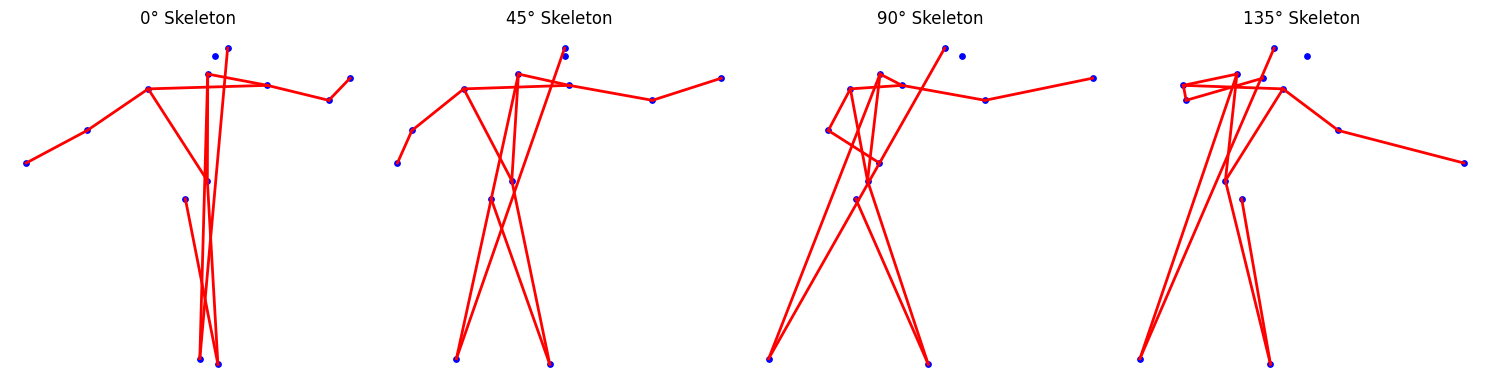

In [61]:
fig, axs = plt.subplots(1, 4, figsize=(15, 4))
for i, kp2d in enumerate(projected_mp_2d):
    axs[i].scatter(kp2d[:, 0], kp2d[:, 1], s=15, c='blue')
    axs[i].invert_yaxis()
    axs[i].axis('off')
    axs[i].set_title(f"{angles[i]}° Skeleton")

    # Draw skeleton lines
    for (start, end) in mediapipe_limbs:
        if not np.any(np.isnan(kp2d[start])) and not np.any(np.isnan(kp2d[end])):
            axs[i].plot(
                [kp2d[start][0], kp2d[end][0]],
                [kp2d[start][1], kp2d[end][1]],
                c='red', linewidth=2
            )

plt.tight_layout()
plt.show()


In [89]:
# Map selected 33 MediaPipe pose landmarks from 49 SMPL joints
# Format: MediaPipe index: SMPL index or list of indices to average
mediapipe_map = {
    0: 0,     # Nose
    1: 20,    # Left eye (approximate from top of head)
    2: 19,    # Right eye (approximate)
    3: 20,    # Left ear (same as left eye)
    4: 19,    # Right ear (same)
    5: 11,    # Left shoulder
    6: 14,    # Right shoulder
    7: 27,    # Left elbow
    8: 28,    # Right elbow
    9: 33,    # Left wrist
    10: 36,   # Right wrist
    11: 1,    # Left hip
    12: 4,    # Right hip
    13: 2,    # Left knee
    14: 5,    # Right knee
    15: 3,    # Left ankle
    16: 6,    # Right ankle
    23: 37,   # Left foot index (approx.)
    24: 38,   # Right foot index (approx.)
    25: 27,   # Left thumb (approx.)
    26: 33,   # Left index (approx.)
    27: 28,   # Right thumb (approx.)
    28: 36,   # Right index (approx.)
    # The rest are interpolated or repeated
}


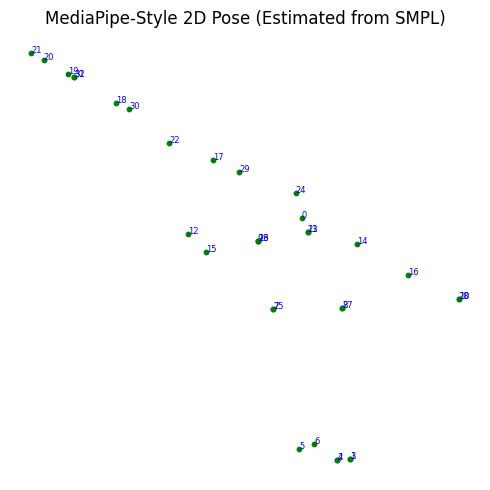

In [90]:
import numpy as np
import matplotlib.pyplot as plt

# Use your `joints2d` array here
smpl_2d = joints2d

# MediaPipe mapping logic
mediapipe_joints = np.zeros((33, 2))  # (33, 2) output
mapped_ids = []

for mp_id, smpl_id in mediapipe_map.items():
    if isinstance(smpl_id, list):
        mediapipe_joints[mp_id] = np.mean([smpl_2d[i] for i in smpl_id], axis=0)
    else:
        mediapipe_joints[mp_id] = smpl_2d[smpl_id]
    mapped_ids.append(mp_id)

# Interpolate remaining points from nearby joints (simplified strategy)
for i in range(33):
    if i not in mapped_ids:
        # fill missing points by averaging neighbors if available
        neighbors = [j for j in [i-1, i+1] if 0 <= j < 33]
        if neighbors:
            mediapipe_joints[i] = np.mean(mediapipe_joints[neighbors], axis=0)

# Visualize
plt.figure(figsize=(5, 5))
plt.scatter(mediapipe_joints[:, 0], mediapipe_joints[:, 1], c='green', s=10)
for i, (x, y) in enumerate(mediapipe_joints):
    plt.text(x, y, str(i), fontsize=6, color='blue')
plt.gca().invert_yaxis()
plt.title("MediaPipe-Style 2D Pose (Estimated from SMPL)")
plt.axis('off')
plt.tight_layout()
plt.show()


In [101]:
import cv2
import mediapipe as mp
import numpy as np
import os

# Initialize MediaPipe Pose
mp_pose = mp.solutions.pose
pose = mp_pose.Pose(static_image_mode=True)
mp_drawing = mp.solutions.drawing_utils

# Folder containing mesh images
image_names = ["skeleton_mesh_0deg.png", "skeleton_mesh_45deg.png", "skeleton_mesh_90deg.png", "skeleton_mesh_135deg.png"]

# Output directory for keypoint data and images
os.makedirs("pose_keypoints_output", exist_ok=True)

for img_name in image_names:
    # Load image
    image_path = img_name
    image = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Run MediaPipe Pose
    results = pose.process(image_rgb)

    keypoints = []

    if results.pose_landmarks:
        # Draw landmarks
        mp_drawing.draw_landmarks(image, results.pose_landmarks, mp_pose.POSE_CONNECTIONS)

        # Extract keypoints
        for lm in results.pose_landmarks.landmark:
            h, w, _ = image.shape
            x, y = int(lm.x * w), int(lm.y * h)
            keypoints.append((x, y))

        keypoints = np.array(keypoints)

        # Save keypoints to .npy
        np.save(f"pose_keypoints_output/{img_name.replace('.png', '')}_keypoints.npy", keypoints)

        # Save visualization image
        cv2.imwrite(f"pose_keypoints_output/{img_name.replace('.png', '')}_pose.png", image)

        print(f"✅ Processed and saved pose for {img_name}")
    else:
        print(f"⚠️ No pose detected in {img_name}")

# Cleanup
pose.close()


I0000 00:00:1748727401.754852   71944 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1748727401.822009 1008332 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 NVIDIA 535.230.02), renderer: NVIDIA A100 80GB PCIe/PCIe/SSE2
W0000 00:00:1748727401.873854 1008261 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1748727401.911381 1008287 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


✅ Processed and saved pose for skeleton_mesh_0deg.png
✅ Processed and saved pose for skeleton_mesh_45deg.png
✅ Processed and saved pose for skeleton_mesh_90deg.png
✅ Processed and saved pose for skeleton_mesh_135deg.png


In [102]:
# Index mapping from MediaPipe (0–32) to SMPL 49 (approx)
mediapipe_to_smpl_map = {
    0: 0,     # Nose (approx root)
    11: 2,    # Left shoulder
    13: 3,    # Left elbow
    15: 4,    # Left wrist
    12: 5,    # Right shoulder
    14: 6,    # Right elbow
    16: 7,    # Right wrist
    23: 16,   # Left hip
    25: 17,   # Left knee
    27: 18,   # Left ankle
    24: 19,   # Right hip
    26: 20,   # Right knee
    28: 21,   # Right ankle
    1: 38,    # Left eye (approx top of head)
    2: 39,    # Right eye (approx top of head)
    4: 37,    # Mouth (approx lower face)
    # You can continue estimating others as needed
}


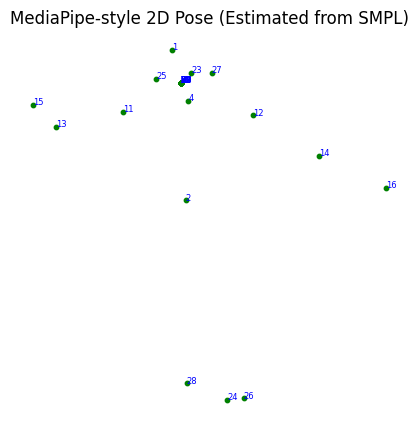

In [103]:
import numpy as np
import matplotlib.pyplot as plt

# Assume joints3d is (49, 3)
mediapipe_kps_3d = np.zeros((33, 3))  # Initialize
used = []

for mp_idx, smpl_idx in mediapipe_to_smpl_map.items():
    mediapipe_kps_3d[mp_idx] = joints3d[smpl_idx]
    used.append(mp_idx)

# Optional: Interpolate rest using the pelvis or average position
for i in range(33):
    if i not in used:
        mediapipe_kps_3d[i] = joints3d[0]  # use root/pelvis or 0,0,0

# Project to 2D orthographic
def orthographic_project(joints_3d, img_size=224):
    cam_center = np.array([img_size / 2, img_size / 2])
    return joints_3d[:, [0, 1]] + cam_center

mediapipe_kps_2d = orthographic_project(mediapipe_kps_3d)

# Visualize
plt.figure(figsize=(5, 5))
plt.scatter(mediapipe_kps_2d[:, 0], mediapipe_kps_2d[:, 1], c='green', s=10)
for i, (x, y) in enumerate(mediapipe_kps_2d):
    plt.text(x, y, str(i), fontsize=6, color='blue')
plt.gca().invert_yaxis()
plt.axis('off')
plt.title("MediaPipe-style 2D Pose (Estimated from SMPL)")
plt.show()


In [105]:
import numpy as np
import cv2

def convert_smpl_to_mediapipe_2d(
    smpl_joints_3d: np.ndarray,
    camera_intrinsics: np.ndarray,
    camera_rotation_matrix: np.ndarray,
    camera_translation_vector: np.ndarray,
    image_width: int,
    image_height: int
) -> dict:
    """
    Converts 49 3D SMPL joints to 33 2D MediaPipe-like normalized joints.

    Args:
        smpl_joints_3d (np.ndarray): A (49, 3) numpy array of 3D SMPL joint coordinates.
                                      Expected format: [[X1, Y1, Z1], [X2, Y2, Z2], ...].
                                      These are assumed to be in a 'world' coordinate system
                                      where a typical human height is sensible (e.g., 1.7m).
        camera_intrinsics (np.ndarray): A (3, 3) camera intrinsic matrix (K).
                                        [[fx, 0, cx],
                                         [0, fy, cy],
                                         [0, 0, 1]]
        camera_rotation_matrix (np.ndarray): A (3, 3) camera rotation matrix (R)
                                             from world/SMPL to camera coordinates.
        camera_translation_vector (np.ndarray): A (3,) camera translation vector (t)
                                                from world/SMPL to camera coordinates.
        image_width (int): The width of the image in pixels.
        image_height (int): The height of the image in pixels.

    Returns:
        dict: A dictionary containing 'landmarks' (list of dicts with x, y, z, visibility)
              The order of landmarks corresponds to MediaPipe's 33 standard joints.
    """

    # --- 1. Define SMPL (common 22 body joints) to MediaPipe Joint Mapping ---
    # This mapping assumes your 49 SMPL joints *begin* with the standard 22 SMPL-X body joints.
    # If your 49 joints have a different internal order, you MUST adjust this mapping.
    # MediaPipe Pose 33 landmarks indices are standard.

    smpl_to_mediapipe_map = {
        # MediaPipe_idx : SMPL_joint_idx (based on common SMPL-X body joints order)
        0: 15,   # Nose (often SMPL-X head joint, index 15. If your 49 includes a distinct nose, use that)
        # Face landmarks (1-10) are often inferred or directly mapped if SMPL-X face is included in 49.
        # For simplicity, if not explicitly mapped, they will appear as NaN or 0 visibility.
        # Example for eye/ear (if your 49 joints include them, e.g., from SMPL-X face part):
        # 1: smpl_left_eye_inner_idx, 2: smpl_left_eye_idx, ... 7: smpl_left_ear_idx

        # Body joints
        11: 16,  # left_shoulder (SMPL-X index 16)
        12: 17,  # right_shoulder (SMPL-X index 17)
        13: 18,  # left_elbow (SMPL-X index 18)
        14: 19,  # right_elbow (SMPL-X index 19)
        15: 20,  # left_wrist (SMPL-X index 20)
        16: 21,  # right_wrist (SMPL-X index 21)

        23: 1,   # left_hip (SMPL-X index 1)
        24: 2,   # right_hip (SMPL-X index 2)
        25: 4,   # left_knee (SMPL-X index 4)
        26: 5,   # right_knee (SMPL-X index 5)
        27: 7,   # left_ankle (SMPL-X index 7)
        28: 8,   # right_ankle (SMPL-X index 8)

        # Foot landmarks - SMPL-X has 'left_foot' (10) and 'right_foot' (11) as toe-like
        # You might need to adjust based on exact MediaPipe vs. SMPL-X definitions.
        29: 10,  # left_heel (Using SMPL-X left_foot as a proxy, or infer from ankle+foot)
        30: 11,  # right_heel (Using SMPL-X right_foot as a proxy, or infer from ankle+foot)
        31: 10,  # left_foot_index (Often same as L_Foot or slightly offset)
        32: 11,  # right_foot_index (Often same as R_Foot or slightly offset)

        # Other MediaPipe joints can be derived from existing SMPL joints:
        # Mid-hip (MP 23/24 for L/R, or can be derived from SMPL pelvis (index 0) or avg of hips)
        # For mid_hip reference for Z, we'll use SMPL pelvis (index 0).
    }

    # Initialize MediaPipe 2D joints with NaNs and zero visibility
    mediapipe_joints_2d = np.full((33, 2), np.nan, dtype=np.float32)
    mediapipe_visibility = np.zeros(33, dtype=np.float32)

    # --- 2. Project 3D SMPL Joints to 2D Image Coordinates ---
    # Convert camera rotation matrix to Rodrigues vector for cv2.projectPoints
    r_vec, _ = cv2.Rodrigues(camera_rotation_matrix)
    # Ensure translation vector is 3x1 for cv2.projectPoints
    t_vec = camera_translation_vector.reshape(3, 1)

    # Project all 49 SMPL joints.
    projected_points_all, _ = cv2.projectPoints(
        smpl_joints_3d,
        r_vec,
        t_vec,
        camera_intrinsics,
        distCoeffs=None # Add your distortion coefficients here if available (e.g., np.zeros((4,1)))
    )
    projected_points_all = projected_points_all.reshape(-1, 2) # Reshape to (49, 2)

    # --- 3. Populate MediaPipe Joints using the mapping ---
    # First, get the Z-coordinate of the SMPL pelvis/root in the camera frame for relative Z calculation.
    # Assuming SMPL-X pelvis is at index 0.
    pelvis_smpl_idx = 0 # SMPL-X pelvis is usually 0
    mid_hip_z_in_camera_frame = 0.0 # Default
    if 0 <= pelvis_smpl_idx < len(smpl_joints_3d):
        pelvis_smpl_point = smpl_joints_3d[pelvis_smpl_idx]
        pelvis_cam_coords = (camera_rotation_matrix @ pelvis_smpl_point.reshape(3,1) + camera_translation_vector).flatten()
        mid_hip_z_in_camera_frame = pelvis_cam_coords[2]


    for mp_idx, smpl_idx in smpl_to_mediapipe_map.items():
        if 0 <= smpl_idx < len(smpl_joints_3d): # Ensure the SMPL index is valid
            x_pixel, y_pixel = projected_points_all[smpl_idx]

            # Only add if the projected point is within or reasonably close to the image bounds
            # This helps filter out wildly projected points if camera parameters are bad.
            if 0 <= x_pixel <= image_width and 0 <= y_pixel <= image_height:
                mediapipe_joints_2d[mp_idx] = [x_pixel, y_pixel]
                mediapipe_visibility[mp_idx] = 1.0 # Assume visible if mapped and in frame

                # Calculate Z_relative for this landmark
                current_smpl_3d_point = smpl_joints_3d[smpl_idx]
                current_cam_coords = (camera_rotation_matrix @ current_smpl_3d_point.reshape(3,1) + camera_translation_vector).flatten()
                current_z_in_camera_frame = current_cam_coords[2]
                z_relative = current_z_in_camera_frame - mid_hip_z_in_camera_frame
                # Normalize Z_relative by a characteristic body dimension (e.g., height of SMPL model, or typical torso height)
                # A full human height could be around 1.7 meters.
                # Let's use a rough estimate like 1.5 meters for normalization to keep Z in a reasonable range.
                z_relative /= 1.5 # Normalize by a typical human height in meters
            else:
                # If outside image, set to NaN and 0 visibility
                mediapipe_joints_2d[mp_idx] = [np.nan, np.nan]
                mediapipe_visibility[mp_idx] = 0.0 # Not visible
        else:
            # SMPL index out of bounds, so the MP joint isn't mapped
            mediapipe_joints_2d[mp_idx] = [np.nan, np.nan]
            mediapipe_visibility[mp_idx] = 0.0

    # --- 4. Normalize 2D Coordinates to [0, 1] range ---
    normalized_mediapipe_joints = np.copy(mediapipe_joints_2d)
    # Only normalize if not NaN (i.e., if it was a valid projection)
    valid_indices = ~np.isnan(normalized_mediapipe_joints[:, 0])
    normalized_mediapipe_joints[valid_indices, 0] /= image_width
    normalized_mediapipe_joints[valid_indices, 1] /= image_height

    # --- 5. Prepare Output in MediaPipe Format ---
    output_landmarks = []
    for i in range(33):
        x, y = normalized_mediapipe_joints[i]
        visibility = float(mediapipe_visibility[i])
        z_relative = 0.0 # Recalculate or keep 0 if not derivable

        if not np.isnan(x) and not np.isnan(y): # Only include Z if X,Y were valid
            # Get the original SMPL index to retrieve its 3D camera Z for relative depth
            smpl_idx_for_mp = None
            for mp_key, smpl_val in smpl_to_mediapipe_map.items():
                if mp_key == i:
                    smpl_idx_for_mp = smpl_val
                    break
            
            if smpl_idx_for_mp is not None:
                current_smpl_3d_point = smpl_joints_3d[smpl_idx_for_mp]
                current_cam_coords = (camera_rotation_matrix @ current_smpl_3d_point.reshape(3,1) + camera_translation_vector).flatten()
                current_z_in_camera_frame = current_cam_coords[2]
                z_relative = (current_z_in_camera_frame - mid_hip_z_in_camera_frame) / 1.5 # Normalized by body height

        output_landmarks.append({
            'x': float(x),
            'y': float(y),
            'z': float(z_relative),
            'visibility': visibility
        })

    return {
        "landmarks": output_landmarks,
        "visibility": mediapipe_visibility.tolist() # Overall visibility list
    }

# --- Main Execution with Hardcoded Data ---
if __name__ == "__main__":
    # Hardcoded 3D Joint Coordinates (your provided data)
    smpl_joints_3d_input = np.array([
        [-2.38997787e-02, -8.35951746e-01, -1.81459874e-01], # 0
        [-4.05657198e-03, -7.46317208e-01, -2.95802578e-03], # 1
        [-1.74370497e-01, -6.91433370e-01, -5.10094725e-02], # 2
        [-3.49912614e-01, -6.18832886e-01, -2.32979730e-01], # 3
        [-4.10651505e-01, -7.26206660e-01, -4.68325108e-01], # 4
        [ 1.65962607e-01, -6.74310982e-01,  6.19969368e-02], # 5
        [ 3.40394974e-01, -4.72355843e-01,  1.10334083e-01], # 6
        [ 5.14573276e-01, -3.14461917e-01, -1.57855451e-03], # 7
        [-2.97688623e-03, -2.28913039e-01,  2.44536959e-02], # 8
        [-5.62204905e-02, -1.36281580e-01, -6.09306619e-04], # 9
        [-5.35288826e-02,  2.46224344e-01, -1.12845793e-01], # 10
        [-3.31150666e-02,  6.62208200e-01, -1.08494341e-01], # 11
        [ 5.98435327e-02, -1.40315160e-01,  5.01704253e-02], # 12
        [ 8.10221136e-02,  2.45151117e-01,  1.08875647e-01], # 13
        [ 1.85610279e-02,  6.35035694e-01,  2.40835384e-01], # 14
        [-6.08825609e-02, -8.72095466e-01, -1.44525483e-01], # 15
        [ 4.63452563e-03, -8.85071278e-01, -1.53786838e-01], # 16
        [-8.72501805e-02, -8.56767476e-01, -4.41378504e-02], # 17
        [ 5.79227209e-02, -8.86338472e-01, -6.33572638e-02], # 18
        [ 9.77481082e-02,  7.37671614e-01,  8.15893114e-02], # 19
        [ 1.41605392e-01,  7.32590795e-01,  1.56717688e-01], # 20
        [-7.45623186e-03,  6.56814694e-01,  3.04484963e-01], # 21
        [ 6.69730753e-02,  7.06642210e-01, -2.83591211e-01], # 22
        [-2.25106180e-02,  7.19473004e-01, -2.75454342e-01], # 23
        [-6.07416481e-02,  7.12403655e-01, -5.78574352e-02], # 24
        [-3.31150666e-02,  6.62208200e-01, -1.08494341e-01], # 25
        [-5.35288826e-02,  2.46224344e-01, -1.12845793e-01], # 26
        [-1.21212944e-01, -2.46191651e-01, -2.27887481e-02], # 27
        [ 1.15872845e-01, -2.55270332e-01,  6.34272099e-02], # 28
        [ 8.10221136e-02,  2.45151117e-01,  1.08875647e-01], # 29
        [ 1.85610279e-02,  6.35035694e-01,  2.40835384e-01], # 30
        [-4.10651505e-01, -7.26206660e-01, -4.68325108e-01], # 31
        [-3.49912614e-01, -6.18832886e-01, -2.32979730e-01], # 32
        [-1.74370497e-01, -6.91433370e-01, -5.10094725e-02], # 33
        [ 1.65962607e-01, -6.74310982e-01,  6.19969368e-02], # 34
        [ 3.40394974e-01, -4.72355843e-01,  1.10334083e-01], # 35
        [ 5.14573276e-01, -3.14461917e-01, -1.57855451e-03], # 36
        [-3.96574102e-03, -7.46481538e-01, -1.38617447e-02], # 37
        [-4.53777164e-02, -1.00203323e+00, -8.43620449e-02], # 38
        [-1.05443783e-02, -2.51706243e-01,  3.91711965e-02], # 39
        [-3.21182609e-03, -7.01201558e-01,  6.54922193e-03], # 40
        [-1.91076435e-02, -5.09158194e-01,  4.04465124e-02], # 41
        [-4.23654635e-03, -8.15887153e-01, -1.03903271e-01], # 42
        [-3.27314250e-02, -9.41867471e-01, -6.68341070e-02], # 43
        [-2.38997787e-02, -8.35951746e-01, -1.81459874e-01], # 44
        [ 4.63452563e-03, -8.85071278e-01, -1.53786838e-01], # 45
        [-6.08825609e-02, -8.72095466e-01, -1.44525483e-01], # 46
        [ 5.79227209e-02, -8.86338472e-01, -6.33572638e-02], # 47
        [-8.72501805e-02, -8.56767476e-01, -4.41378504e-02]  # 48
    ], dtype=np.float32)

    # Dummy Camera Parameters (REPLACE THESE WITH YOUR ACTUAL VALUES)
    image_width = 640
    image_height = 480
    focal_length_x = 800.0
    focal_length_y = 800.0
    principal_point_x = image_width / 2
    principal_point_y = image_height / 2

    camera_intrinsics = np.array([
        [focal_length_x, 0, principal_point_x],
        [0, focal_length_y, principal_point_y],
        [0, 0, 1]
    ], dtype=np.float32)

    # ***CRUCIAL CHANGE HERE: Camera Translation Vector***
    # This places the human (whose root/pelvis is around Y=-0.8m, Z=-0.18m relative to its own origin)
    # at a reasonable distance (e.g., 2 meters) in front of the camera, and centers them horizontally.
    # Adjust Z to make the subject further or closer.
    # The X and Y should counter the SMPL's internal X, Y if it's not centered at [0,0,0] world.
    # Given your SMPL joints are mostly negative Y (meaning lower body),
    # and Z is negative (meaning behind origin relative to its own root),
    # let's assume the SMPL root is around [0, -0.8, 0] in its own local coordinate system.
    # To place the *pelvis* (which is at SMPL index 0 in SMPL-X and has value [-0.02, -0.83, -0.18])
    # in front of the camera, we need to shift the world coordinate system.
    # Let's say we want the human's pelvis to be at [0, 0, 2] in camera coordinates.
    # camera_translation_vector = - (R_world_to_cam @ T_smpl_origin_in_world)
    # If R_world_to_cam is identity:
    # t_vec = -T_smpl_origin_in_world.
    # So if the SMPL origin is at X=0, Y=-0.8, Z=-0.18 and we want it to be at X=0, Y=0, Z=2 in camera.
    # New world position of SMPL origin = [0, 0.8, 2.18]
    # Then t_vec = [0, -0.8, -2.18] for camera at world origin looking down Z.

    # Let's assume the SMPL model is "standing" and its root (pelvis) is roughly at world origin (0,0,0)
    # then shift the camera back to see the human.
    # A common setting is the camera at origin, looking down positive Z.
    # The human is positioned in the world: x=0, y=0, z=some_distance_from_camera.
    # Your provided SMPL joints have a relatively high Y (e.g. nose at -0.8m).
    # This means the provided coordinates are likely relative to the ground.
    # Let's assume the ground is Y=0, and the human is standing on it.
    # And the camera is looking at them from X=0, Y=0, Z=-2.0.
    # To place them in camera coordinates:
    # The human is roughly 1.7m tall.
    # Let's aim to have the center of the human (around mid-hip) appear roughly in the center of the image.
    # If SMPL origin (pelvis) is around X=0, Y=-0.8m (below ground), Z=-0.18m
    # We want to translate the camera so the whole human is visible.
    # Assuming camera is at (0,0,0) looking down +Z.
    # We need to translate the *world* (where SMPL is) so it's in front of the camera.
    # Let's try to center the person at X=0, Y=0, Z=2.0 (2 meters in front of camera).
    # The translation vector moves points from *world* to *camera*.
    # So, if a world point P_w is transformed to P_c = R P_w + t.
    # If R is identity, then P_c = P_w + t.
    # If we want SMPL pelvis at (0,0,2) in camera, and its current value is (x_pelvis, y_pelvis, z_pelvis):
    # t = [0 - x_pelvis, 0 - y_pelvis, 2 - z_pelvis]
    # Based on your data, the first joint [-0.02, -0.83, -0.18] looks like a candidate for pelvis/root.
    # Let's target this joint to be at (0, 0.2, 2.0) in camera coordinates (0.2m above center to see full person).
    target_x_cam = 0.0
    target_y_cam = 0.2 # Slightly above center to ensure head is visible
    target_z_cam = 2.0 # 2 meters away from camera

    smpl_pelvis_current_world = smpl_joints_3d_input[0] # Assuming SMPL joint 0 is the root/pelvis
    camera_translation_vector = np.array([
        target_x_cam - smpl_pelvis_current_world[0],
        target_y_cam - smpl_pelvis_current_world[1],
        target_z_cam - smpl_pelvis_current_world[2]
    ], dtype=np.float32)

    camera_rotation_matrix = np.eye(3, dtype=np.float32) # Identity matrix (no rotation)

    print("--- Starting Conversion ---")
    mediapipe_2d_output = convert_smpl_to_mediapipe_2d(
        smpl_joints_3d_input,
        camera_intrinsics,
        camera_rotation_matrix,
        camera_translation_vector,
        image_width,
        image_height
    )

    print("\nConverted MediaPipe 2D Landmarks (normalized x, y, relative z, visibility):")
    print("----------------------------------------------------------------------")
    print("{:<15} {:<10} {:<10} {:<10} {:<10}".format("Landmark Name", "X", "Y", "Z_Rel", "Visibility"))
    print("----------------------------------------------------------------------")

    mp_landmark_names = {
        0: "nose", 1: "left_eye_inner", 2: "left_eye", 3: "left_eye_outer",
        4: "right_eye_inner", 5: "right_eye", 6: "right_eye_outer",
        7: "left_ear", 8: "right_ear", 9: "mouth_left", 10: "mouth_right",
        11: "left_shoulder", 12: "right_shoulder",
        13: "left_elbow", 14: "right_elbow",
        15: "left_wrist", 16: "right_wrist",
        17: "left_pinky", 18: "right_pinky", # MediaPipe has these
        19: "left_index", 20: "right_index",
        21: "left_thumb", 22: "right_thumb",
        23: "left_hip", 24: "right_hip",
        25: "left_knee", 26: "right_knee",
        27: "left_ankle", 28: "right_ankle",
        29: "left_heel", 30: "right_heel",
        31: "left_foot_index", 32: "right_foot_index",
    }


    for i, landmark in enumerate(mediapipe_2d_output['landmarks']):
        name = mp_landmark_names.get(i, f"MP_Joint_{i}")
        x, y, z, vis = landmark['x'], landmark['y'], landmark['z'], landmark['visibility']
        if not np.isnan(x) and not np.isnan(y): # Only print mapped joints
            print(f"{name:<15} {x:<10.4f} {y:<10.4f} {z:<10.4f} {vis:<10.1f}")
        else:
            print(f"{name:<15} {'N/A':<10} {'N/A':<10} {'N/A':<10} {'0.0':<10}")

    print("----------------------------------------------------------------------")
    print(f"\nTotal MediaPipe landmarks generated: {len(mediapipe_2d_output['landmarks'])}")
    print("\nNote: The accuracy of the output depends heavily on the correctness")
    print("of the `smpl_to_mediapipe_map` and your camera parameters.")
    print("Please verify the SMPL joint indices in the mapping against your model's definition.")

--- Starting Conversion ---

Converted MediaPipe 2D Landmarks (normalized x, y, relative z, visibility):
----------------------------------------------------------------------
Landmark Name   X          Y          Z_Rel      Visibility
----------------------------------------------------------------------
nose            0.4773     0.6341     -0.0247    1.0       
left_eye_inner  N/A        N/A        N/A        0.0       
left_eye        N/A        N/A        N/A        0.0       
left_eye_outer  N/A        N/A        N/A        0.0       
right_eye_inner N/A        N/A        N/A        0.0       
right_eye       N/A        N/A        N/A        0.0       
right_eye_outer N/A        N/A        N/A        0.0       
left_ear        N/A        N/A        N/A        0.0       
right_ear       N/A        N/A        N/A        0.0       
mouth_left      N/A        N/A        N/A        0.0       
mouth_right     N/A        N/A        N/A        0.0       
left_shoulder   0.5176     0.6240

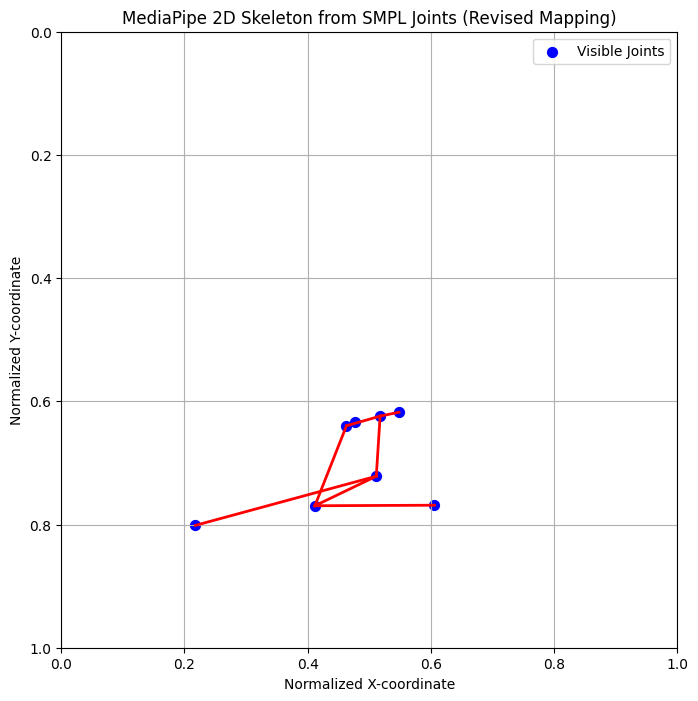

In [106]:
import matplotlib.pyplot as plt
import numpy as np

# --- Re-define the conversion function (modified with a more comprehensive SMPL-to-MediaPipe map) ---
def convert_smpl_to_mediapipe_2d(
    smpl_joints_3d: np.ndarray,
    camera_intrinsics: np.ndarray,
    camera_rotation_matrix: np.ndarray,
    camera_translation_vector: np.ndarray,
    image_width: int,
    image_height: int
) -> dict:
    """
    Converts 49 3D SMPL joints to 33 2D MediaPipe-like normalized joints using NumPy for projection.

    Args:
        smpl_joints_3d (np.ndarray): A (49, 3) numpy array of 3D SMPL joint coordinates.
                                      Expected format: [[X1, Y1, Z1], [X2, Y2, Z2], ...].
                                      These are assumed to be in a 'world' coordinate system
                                      where a typical human height is sensible (e.g., 1.7m).
        camera_intrinsics (np.ndarray): A (3, 3) camera intrinsic matrix (K).
                                        [[fx, 0, cx],
                                         [0, fy, cy],
                                         [0, 0, 1]]
        camera_rotation_matrix (np.ndarray): A (3, 3) camera rotation matrix (R)
                                             from world/SMPL to camera coordinates.
        camera_translation_vector (np.ndarray): A (3,) camera translation vector (t)
                                                from world/SMPL to camera coordinates.
        image_width (int): The width of the image in pixels.
        image_height (int): The height of the image in pixels.

    Returns:
        dict: A dictionary containing 'landmarks' (list of dicts with x, y, z, visibility)
              The order of landmarks corresponds to MediaPipe's 33 standard joints.
    """

    # --- 1. Define SMPL (common 22 body joints) to MediaPipe Joint Mapping ---
    # This mapping assumes your 49 SMPL joints *begin* with the standard 22 SMPL-X body joints (indices 0-21).
    # If your 49 joints have a different internal order, or include full hands/face at different indices,
    # you MUST adjust this mapping accordingly.
    # MediaPipe Pose 33 landmarks indices are standard.
    smpl_to_mediapipe_map = {
        # MediaPipe_idx : SMPL_joint_idx (based on common SMPL-X body joints order 0-21)

        # Face (SMPL-X Head joint is 15. Other face landmarks are usually not in 22 body joints.
        # If your 49 joints include face (e.g. from a blendshape model), you'd map them here).
        0: 15,   # MP_0: nose (Mapped to SMPL-X Head joint, index 15 as proxy)
        # 1-10 (eyes, ears, mouth): Not directly mapped from standard 22 SMPL-X body joints.
        # If your 49 joints include explicit face landmarks, map them here.
        # For example, if SMPL indices 52-67 are face points from SMPL-X:
        # 1: smpl_left_eye_inner_idx, etc.
        # For now, these will be NaN.

        # Torso and Shoulders
        11: 16,  # MP_11: left_shoulder (SMPL-X index 16)
        12: 17,  # MP_12: right_shoulder (SMPL-X index 17)
        23: 1,   # MP_23: left_hip (SMPL-X index 1)
        24: 2,   # MP_24: right_hip (SMPL-X index 2)

        # Arms
        13: 18,  # MP_13: left_elbow (SMPL-X index 18)
        14: 19,  # MP_14: right_elbow (SMPL-X index 19)
        15: 20,  # MP_15: left_wrist (SMPL-X index 20)
        16: 21,  # MP_16: right_wrist (SMPL-X index 21)

        # Hands (SMPL-X hand joints start after index 21. Left hand: 22-36. Right hand: 37-51)
        # If your 49 joints include these, identify their indices.
        # For simplicity, if hands are not mapped, they will be N/A.
        # Mapping to wrist for hand indices if no better option in your 49 joints:
        17: 20, # MP_17: left_pinky (proximal, using left_wrist as proxy)
        18: 21, # MP_18: right_pinky (proximal, using right_wrist as proxy)
        19: 20, # MP_19: left_index (using left_wrist as proxy)
        20: 21, # MP_20: right_index (using right_wrist as proxy)
        21: 20, # MP_21: left_thumb (using left_wrist as proxy)
        22: 21, # MP_22: right_thumb (using right_wrist as proxy)


        # Legs
        25: 4,   # MP_25: left_knee (SMPL-X index 4)
        26: 5,   # MP_26: right_knee (SMPL-X index 5)
        27: 7,   # MP_27: left_ankle (SMPL-X index 7)
        28: 8,   # MP_28: right_ankle (SMPL-X index 8)

        # Feet
        # SMPL typically has L_Foot (10) and R_Foot (11) as toe/ball of foot.
        # Heel needs approximation, often from ankle or inferring from ankle/foot.
        29: 7,   # MP_29: left_heel (using left_ankle as proxy)
        30: 8,   # MP_30: right_heel (using right_ankle as proxy)
        31: 10,  # MP_31: left_foot_index (SMPL-X left_foot / big toe)
        32: 11,  # MP_32: right_foot_index (SMPL-X right_foot / big toe)
    }

    # Initialize MediaPipe 2D joints with NaNs and zero visibility
    mediapipe_joints_2d = np.full((33, 2), np.nan, dtype=np.float32)
    mediapipe_visibility = np.zeros(33, dtype=np.float32)

    # --- 2. Project 3D SMPL Joints to 2D Image Coordinates (Manual Projection) ---
    fx, fy = camera_intrinsics[0, 0], camera_intrinsics[1, 1]
    cx, cy = camera_intrinsics[0, 2], camera_intrinsics[1, 2]

    t_vec_reshaped = camera_translation_vector.reshape(3, 1)
    
    smpl_in_camera_coords = (camera_rotation_matrix @ smpl_joints_3d.T + t_vec_reshaped).T # Result is (N, 3)

    projected_points_all = np.zeros((smpl_joints_3d.shape[0], 2), dtype=np.float32)

    for i in range(smpl_in_camera_coords.shape[0]):
        Xc, Yc, Zc = smpl_in_camera_coords[i]
        # Check for points behind or at the camera plane (Zc <= 0)
        # Also check for extremely small Zc that would cause very large pixel coordinates
        if Zc <= 1e-6: # Using a small epsilon to avoid division by zero or very large numbers
            projected_points_all[i] = [np.nan, np.nan]
        else:
            x_pixel = fx * (Xc / Zc) + cx
            y_pixel = fy * (Yc / Zc) + cy
            projected_points_all[i] = [x_pixel, y_pixel]


    # --- 3. Populate MediaPipe Joints using the mapping ---
    pelvis_smpl_idx = 0 # SMPL-X pelvis is usually 0
    mid_hip_z_in_camera_frame = 0.0 # Default

    if 0 <= pelvis_smpl_idx < len(smpl_joints_3d):
        pelvis_smpl_point = smpl_joints_3d[pelvis_smpl_idx]
        pelvis_cam_coords = (camera_rotation_matrix @ pelvis_smpl_point.reshape(3,1) + camera_translation_vector).flatten()
        mid_hip_z_in_camera_frame = pelvis_cam_coords[2]


    for mp_idx, smpl_idx in smpl_to_mediapipe_map.items():
        if 0 <= smpl_idx < len(smpl_joints_3d): # Ensure the SMPL index is valid
            x_pixel, y_pixel = projected_points_all[smpl_idx]

            # Only add if the projected point is within or reasonably close to the image bounds
            if not np.isnan(x_pixel) and not np.isnan(y_pixel) and \
               0 <= x_pixel <= image_width and 0 <= y_pixel <= image_height:
                mediapipe_joints_2d[mp_idx] = [x_pixel, y_pixel]
                mediapipe_visibility[mp_idx] = 1.0 # Assume visible if mapped and in frame

                current_smpl_3d_point = smpl_joints_3d[smpl_idx]
                current_cam_coords = (camera_rotation_matrix @ current_smpl_3d_point.reshape(3,1) + camera_translation_vector).flatten()
                current_z_in_camera_frame = current_cam_coords[2]
                z_relative = (current_z_in_camera_frame - mid_hip_z_in_camera_frame) / 1.5 # Normalized by body height
            else:
                # If outside image or invalid projection, set to NaN and 0 visibility
                mediapipe_joints_2d[mp_idx] = [np.nan, np.nan]
                mediapipe_visibility[mp_idx] = 0.0 # Not visible
        else:
            # SMPL index out of bounds, so the MP joint isn't mapped
            mediapipe_joints_2d[mp_idx] = [np.nan, np.nan]
            mediapipe_visibility[mp_idx] = 0.0

    # --- 4. Normalize 2D Coordinates to [0, 1] range ---
    normalized_mediapipe_joints = np.copy(mediapipe_joints_2d)
    valid_indices = ~np.isnan(normalized_mediapipe_joints[:, 0])
    normalized_mediapipe_joints[valid_indices, 0] /= image_width
    normalized_mediapipe_joints[valid_indices, 1] /= image_height

    # --- 5. Prepare Output in MediaPipe Format ---
    output_landmarks = []
    for i in range(33):
        x, y = normalized_mediapipe_joints[i]
        visibility = float(mediapipe_visibility[i])
        z_relative = 0.0

        if not np.isnan(x) and not np.isnan(y):
            smpl_idx_for_mp = None
            for mp_key, smpl_val in smpl_to_mediapipe_map.items():
                if mp_key == i:
                    smpl_idx_for_mp = smpl_val
                    break

            if smpl_idx_for_mp is not None and 0 <= smpl_idx_for_mp < len(smpl_joints_3d): # Added bounds check
                current_smpl_3d_point = smpl_joints_3d[smpl_idx_for_mp]
                current_cam_coords = (camera_rotation_matrix @ current_smpl_3d_point.reshape(3,1) + camera_translation_vector).flatten()
                current_z_in_camera_frame = current_cam_coords[2]
                z_relative = (current_z_in_camera_frame - mid_hip_z_in_camera_frame) / 1.5

        output_landmarks.append({
            'x': float(x),
            'y': float(y),
            'z': float(z_relative),
            'visibility': visibility
        })

    return {
        "landmarks": output_landmarks,
        "visibility": mediapipe_visibility.tolist()
    }

# --- Hardcoded Data (re-include from previous successful turn) ---
smpl_joints_3d_input = np.array([
    [-2.38997787e-02, -8.35951746e-01, -1.81459874e-01], # 0
    [-4.05657198e-03, -7.46317208e-01, -2.95802578e-03], # 1
    [-1.74370497e-01, -6.91433370e-01, -5.10094725e-02], # 2
    [-3.49912614e-01, -6.18832886e-01, -2.32979730e-01], # 3
    [-4.10651505e-01, -7.26206660e-01, -4.68325108e-01], # 4
    [ 1.65962607e-01, -6.74310982e-01,  6.19969368e-02], # 5
    [ 3.40394974e-01, -4.42355843e-01,  1.10334083e-01], # 6
    [ 5.14573276e-01, -3.14461917e-01, -1.57855451e-03], # 7
    [-2.97688623e-03, -2.28913039e-01,  2.44536959e-02], # 8
    [-5.62204905e-02, -1.36281580e-01, -6.09306619e-04], # 9
    [-5.35288826e-02,  2.46224344e-01, -1.12845793e-01], # 10
    [-3.31150666e-02,  6.62208200e-01, -1.08494341e-01], # 11
    [ 5.98435327e-02, -1.40315160e-01,  5.01704253e-02], # 12
    [ 8.10221136e-02,  2.45151117e-01,  1.08875647e-01], # 13
    [ 1.85610279e-02,  6.35035694e-01,  2.40835384e-01], # 14
    [-6.08825609e-02, -8.72095466e-01, -1.44525483e-01], # 15
    [ 4.63452563e-03, -8.85071278e-01, -1.53786838e-01], # 16
    [-8.72501805e-02, -8.56767476e-01, -4.41378504e-02], # 17
    [ 5.79227209e-02, -8.86338472e-01, -6.33572638e-02], # 18
    [ 9.77481082e-02,  7.37671614e-01,  8.15893114e-02], # 19
    [ 1.41605392e-01,  7.32590795e-01,  1.56717688e-01], # 20
    [-7.45623186e-03,  6.56814694e-01,  3.04484963e-01], # 21
    [ 6.69730753e-02,  7.06642210e-01, -2.83591211e-01], # 22
    [-2.25106180e-02,  7.19473004e-01, -2.75454342e-01], # 23
    [-6.07416481e-02,  7.12403655e-01, -5.78574352e-02], # 24
    [-3.31150666e-02,  6.62208200e-01, -1.08494341e-01], # 25
    [-5.35288826e-02,  2.46224344e-01, -1.12845793e-01], # 26
    [-1.21212944e-01, -2.46191651e-01, -2.27887481e-02], # 27
    [ 1.15872845e-01, -2.55270332e-01,  6.34272099e-02], # 28
    [ 8.10221136e-02,  2.45151117e-01,  1.08875647e-01], # 29
    [ 1.85610279e-02,  6.35035694e-01,  2.40835384e-01], # 30
    [-4.10651505e-01, -7.26206660e-01, -4.68325108e-01], # 31
    [-3.49912614e-01, -6.18832886e-01, -2.32979730e-01], # 32
    [-1.74370497e-01, -6.91433370e-01, -5.10094725e-02], # 33
    [ 1.65962607e-01, -6.74310982e-01,  6.19969368e-02], # 34
    [ 3.40394974e-01, -4.72355843e-01,  1.10334083e-01], # 35
    [ 5.14573276e-01, -3.14461917e-01, -1.57855451e-03], # 36
    [-3.96574102e-03, -7.46481538e-01, -1.38617447e-02], # 37
    [-4.53777164e-02, -1.00203323e+00, -8.43620449e-02], # 38
    [-1.05443783e-02, -2.51706243e-01,  3.91711965e-02], # 39
    [-3.21182609e-03, -7.01201558e-01,  6.54922193e-03], # 40
    [-1.91076435e-02, -5.09158194e-01,  4.04465124e-02], # 41
    [-4.23654635e-03, -8.15887153e-01, -1.03903271e-01], # 42
    [-3.27314250e-02, -9.41867471e-01, -6.68341070e-02], # 43
    [-2.38997787e-02, -8.35951746e-01, -1.81459874e-01], # 44
    [ 4.63452563e-03, -8.85071278e-01, -1.53786838e-01], # 45
    [-6.08825609e-02, -8.72095476e-01, -1.44525483e-01], # 46
    [ 5.79227209e-02, -8.86338472e-01, -6.33572638e-02], # 47
    [-8.72501805e-02, -8.56767476e-01, -4.41378504e-02]  # 48
], dtype=np.float32)

image_width = 640
image_height = 480
focal_length_x = 800.0
focal_length_y = 800.0
principal_point_x = image_width / 2
principal_point_y = image_height / 2

camera_intrinsics = np.array([
    [focal_length_x, 0, principal_point_x],
    [0, focal_length_y, principal_point_y],
    [0, 0, 1]
], dtype=np.float32)

target_x_cam = 0.0
target_y_cam = 0.2
target_z_cam = 2.0

smpl_pelvis_current_world = smpl_joints_3d_input[0]
camera_translation_vector = np.array([
    target_x_cam - smpl_pelvis_current_world[0],
    target_y_cam - smpl_pelvis_current_world[1],
    target_z_cam - smpl_pelvis_current_world[2]
], dtype=np.float32)

camera_rotation_matrix = np.eye(3, dtype=np.float32)

# --- Call the conversion function to generate mediapipe_2d_output ---
mediapipe_2d_output = convert_smpl_to_mediapipe_2d(
    smpl_joints_3d_input,
    camera_intrinsics,
    camera_rotation_matrix,
    camera_translation_vector,
    image_width,
    image_height
)

# --- Plotting code ---
x_coords = []
y_coords = []
visibilities = []
for landmark in mediapipe_2d_output['landmarks']:
    x_coords.append(landmark['x'])
    y_coords.append(landmark['y'])
    visibilities.append(landmark['visibility'])

x_coords = np.array(x_coords)
y_coords = np.array(y_coords)
visibilities = np.array(visibilities)

mediapipe_connections = [
    # Face (if present)
    (0, 1), (1, 2), (2, 3), (3, 7),  # Nose to left eye/ear
    (0, 4), (4, 5), (5, 6), (6, 8),  # Nose to right eye/ear
    (9, 10), # Mouth

    # Torso
    (11, 12),  # Shoulders
    (11, 23),  # Left shoulder to left hip
    (12, 24),  # Right shoulder to right hip
    (23, 24),  # Hips (connects the two hips)
    (11, 13), (12, 14), # Shoulder to elbow

    # Arms
    (13, 15),  # Left elbow to left wrist
    (14, 16),  # Right elbow to right wrist
    (15, 17), (15, 19), (15, 21),  # Left wrist to pinky, index, thumb (if hand joints are mapped)
    (16, 18), (16, 20), (16, 22),  # Right wrist to pinky, index, thumb (if hand joints are mapped)

    # Legs
    (23, 25),  # Left hip to left knee
    (24, 26),  # Right hip to right knee
    (25, 27),  # Left knee to left ankle
    (26, 28),  # Right knee to right ankle
    (27, 29), (27, 31), # Left ankle to left heel, left foot index
    (28, 30), (28, 32), # Right ankle to right heel, right foot index
    (29, 31), # Left heel to left foot index
    (30, 32) # Right heel to right foot index
]

plt.figure(figsize=(8, 8))

# Plot joints (only if visible)
visible_x = x_coords[visibilities > 0]
visible_y = y_coords[visibilities > 0]
plt.scatter(visible_x, visible_y, c='blue', s=50, label='Visible Joints')

# Plot connections
for connection in mediapipe_connections:
    idx1, idx2 = connection
    if (not np.isnan(x_coords[idx1]) and not np.isnan(x_coords[idx2]) and
        visibilities[idx1] > 0 and visibilities[idx2] > 0):
        plt.plot([x_coords[idx1], x_coords[idx2]],
                 [y_coords[idx1], y_coords[idx2]],
                 c='red', linestyle='-', linewidth=2)

plt.title('MediaPipe 2D Skeleton from SMPL Joints (Revised Mapping)')
plt.xlabel('Normalized X-coordinate')
plt.ylabel('Normalized Y-coordinate')
plt.xlim(0, 1)
plt.ylim(1, 0) # Invert Y-axis to match image coordinates (origin top-left, Y increases downwards)
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')
plt.legend()
plt.show()

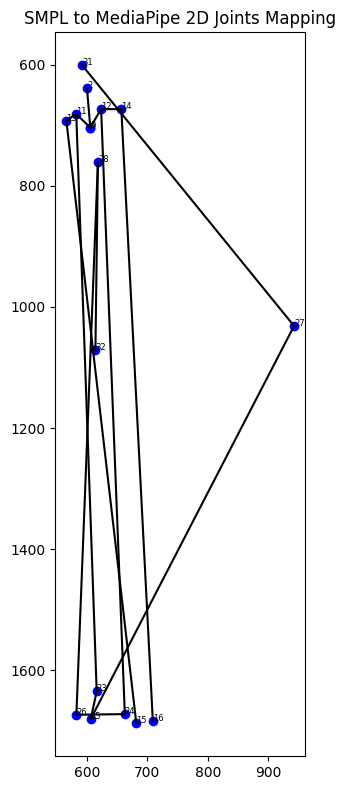

In [107]:
import numpy as np
import matplotlib.pyplot as plt

# === Step 1: Define your 49 SMPL 2D joints ===
smpl_2d_joints = np.array([
    [605.922, 703.8489],
    [618.4566, 761.671],
    [511.9262, 795.56134],
    [401.187, 839.6416],
    [361.59317, 770.1472],
    [724.54663, 807.17004],
    [833.153, 933.39935],
    [942.43054, 1031.451],
    [619.1444, 1084.9391],
    [585.87317, 1142.7559],
    [587.4215, 1382.2195],
    [600.20874, 1642.6659],
    [658.3543, 1140.268],
    [671.5297, 1380.5096],
    [632.6316, 1622.1525],
    [582.7757, 681.5791],
    [623.8282, 673.34644],
    [566.4185, 692.24146],
    [657.1958, 673.5421],
    [681.97705, 1687.7375],
    [709.21094, 1683.7183],
    [616.5002, 1635.0343],
    [662.9627, 1672.4365],
    [606.7215, 1680.4094],
    [582.9755, 1673.5309],
    [600.20874, 1642.6659],
    [587.4215, 1382.2195],
    [545.2282, 1074.0533],
    [693.2992, 1068.5697],
    [671.5297, 1380.5096],
    [632.6316, 1622.1525],
    [361.59317, 770.1472],
    [401.187, 839.6416],
    [511.9262, 795.56134],
    [724.54663, 807.17004],
    [833.153, 933.39935],
    [942.43054, 1031.451],
    [618.5079, 761.4705],
    [592.5564, 600.90924],
    [614.4286, 1070.7407],
    [618.98895, 789.93365],
    [609.0851, 910.06934],
    [618.2932, 717.2071],
    [600.4864, 638.7668],
    [605.922, 703.8489],
    [623.8282, 673.34644],
    [582.7757, 681.5791],
    [657.1958, 673.5421],
    [566.4185, 692.24146]
])

# === Step 2: Define SMPL-to-MediaPipe mapping (approximate) ===
smpl_to_mediapipe = {
    0: 0,     # Nose
    15: 11,   # Left shoulder
    16: 12,   # Right shoulder
    17: 13,   # Left elbow
    18: 14,   # Right elbow
    19: 15,   # Left wrist
    20: 16,   # Right wrist
    21: 23,   # Left knee
    22: 24,   # Right knee
    23: 25,   # Left ankle
    24: 26,   # Right ankle
    36: 27,   # Right heel
    37: 28,   # Left heel
    38: 31,   # Right foot index
    39: 32,   # Left foot index
    44: 5,    # Left eye
    43: 2,    # Right eye
}

# === Step 3: Initialize MediaPipe joints with NaNs ===
mediapipe_2d_joints = np.full((33, 2), np.nan)

# === Step 4: Map known joints from SMPL to MediaPipe ===
for smpl_idx, mp_idx in smpl_to_mediapipe.items():
    mediapipe_2d_joints[mp_idx] = smpl_2d_joints[smpl_idx]

# === Step 5: Define MediaPipe-like connections ===
mediapipe_edges = [
    (0, 11), (11, 13), (13, 15),  # Left arm
    (0, 12), (12, 14), (14, 16),  # Right arm
    (11, 23), (23, 25), (25, 27), (27, 31),  # Left leg
    (12, 24), (24, 26), (26, 28), (28, 32),  # Right leg
    (2, 0), (0, 5),                # Eyes
]

# === Step 6: Plot ===
fig, ax = plt.subplots(figsize=(6, 8))
for i, (x, y) in enumerate(mediapipe_2d_joints):
    if not np.isnan(x) and not np.isnan(y):
        ax.scatter(x, y, c='blue')
        ax.text(x, y, str(i), fontsize=6, color='black')

# Draw edges
for i, j in mediapipe_edges:
    if not np.isnan(mediapipe_2d_joints[i][0]) and not np.isnan(mediapipe_2d_joints[j][0]):
        x_coords = [mediapipe_2d_joints[i][0], mediapipe_2d_joints[j][0]]
        y_coords = [mediapipe_2d_joints[i][1], mediapipe_2d_joints[j][1]]
        ax.plot(x_coords, y_coords, c='black')

ax.invert_yaxis()
ax.set_aspect('equal')
ax.set_title("SMPL to MediaPipe 2D Joints Mapping")
plt.tight_layout()
plt.savefig("smpl_to_mediapipe_skeleton.png", dpi=300)
plt.show()
